In [2]:
!pip install medmnist opencv-python scikit-image scikit-learn matplotlib numpy

import numpy as np
import cv2
import matplotlib.pyplot as plt
from medmnist import BloodMNIST
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# ---------- PERSONAL SETTINGS (FA23-BAI-045) ----------
REG_NO     = "FA23-BAI-045"
SEED       = 45                # last two digits
HOG_CELL   = (16, 16)          # last digit 5 is odd
SIFT_GRID  = 6                 # last digit 5 is in 5-9 -> 6 x 6 = 36 keypoints

# ---------- FIXED SETTINGS (same for everyone) ----------
CLASSES      = {1: "eosinophil", 5: "monocyte", 6: "neutrophil", 7: "platelet"}
N_TRAIN, N_VAL, N_TEST = 100, 30, 30
IMG_SIZE     = 128
HOG_ORIENT   = 9
HOG_BLOCK    = (2, 2)
C_VALUES     = [0.1, 1, 10]
ROT_ANGLE    = 20
NOISE_SIGMA  = 0.05
KP_SIZE      = 32

np.random.seed(SEED)

print("Reg No        :", REG_NO)
print("Seed          :", SEED)
print("HOG cell size :", HOG_CELL)
print("SIFT grid     :", f"{SIFT_GRID} x {SIFT_GRID} = {SIFT_GRID**2} keypoints")
print("Classes       :", CLASSES)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [medmnist]
Reg No        : FA23-BAI-045
Seed          : 45
HOG cell size : (16, 16)
SIFT grid     : 6 x 6 = 36 keypoints
Classes       : {1: 'eosinophil', 5: 'monocyte', 6: 'neutrophil', 7: 'platelet'}


# Q1. Data Setup
Load BloodMNIST (size 64), keep 4 classes, take 100 train / 30 val / 30 test images per class (chosen with seed 45), convert to grayscale and resize to 128 x 128.

In [3]:
rng = np.random.RandomState(SEED)   # one generator, so the choice is reproducible

def load_subset(split, n_per_class):
    ds = BloodMNIST(split=split, download=True, size=64)
    imgs   = ds.imgs                    # shape (N, 64, 64, 3), RGB uint8
    labels = ds.labels.flatten()        # shape (N,)

    X, y = [], []
    for lab in CLASSES:                 # only the 4 chosen classes
        idx = np.where(labels == lab)[0]
        chosen = rng.choice(idx, n_per_class, replace=False)   # random pick using seed
        for i in chosen:
            gray = cv2.cvtColor(imgs[i], cv2.COLOR_RGB2GRAY)    # grayscale
            gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE))       # 128 x 128
            X.append(gray)
            y.append(lab)
    return np.array(X, dtype=np.uint8), np.array(y)

X_train, y_train = load_subset("train", N_TRAIN)
X_val,   y_val   = load_subset("val",   N_VAL)
X_test,  y_test  = load_subset("test",  N_TEST)

for name, X, y in [("Train", X_train, y_train),
                   ("Val",   X_val,   y_val),
                   ("Test",  X_test,  y_test)]:
    labs, counts = np.unique(y, return_counts=True)
    print(f"{name:5s} X shape: {X.shape}, y shape: {y.shape}, dtype: {X.dtype}")
    for l, c in zip(labs, counts):
        print(f"      class {l} ({CLASSES[l]}): {c}")
    print()

100%|██████████| 156M/156M [02:06<00:00, 1.23MB/s]


Train X shape: (400, 128, 128), y shape: (400,), dtype: uint8
      class 1 (eosinophil): 100
      class 5 (monocyte): 100
      class 6 (neutrophil): 100
      class 7 (platelet): 100

Val   X shape: (120, 128, 128), y shape: (120,), dtype: uint8
      class 1 (eosinophil): 30
      class 5 (monocyte): 30
      class 6 (neutrophil): 30
      class 7 (platelet): 30

Test  X shape: (120, 128, 128), y shape: (120,), dtype: uint8
      class 1 (eosinophil): 30
      class 5 (monocyte): 30
      class 6 (neutrophil): 30
      class 7 (platelet): 30



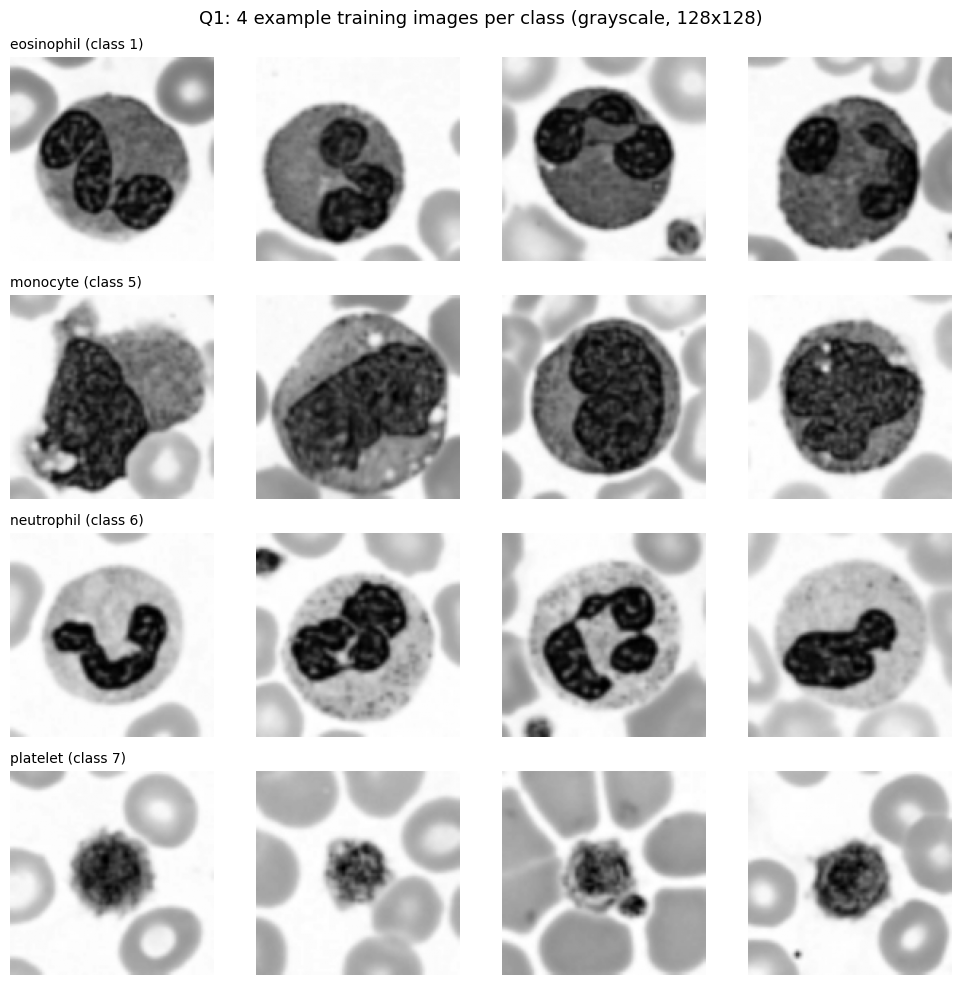

In [4]:
# 4 example images per class (rows = classes, columns = examples)
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(10, 10))

for r, (lab, name) in enumerate(CLASSES.items()):
    idx = np.where(y_train == lab)[0][:4]        # first 4 training images of this class
    for c, i in enumerate(idx):
        axes[r, c].imshow(X_train[i], cmap="gray")
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(f"{name} (class {lab})", fontsize=10, loc="left")

plt.suptitle("Q1: 4 example training images per class (grayscale, 128x128)", fontsize=13)
plt.tight_layout()
plt.show()

# Q2. HOG + SVM

In [5]:
def extract_hog(img):
    return hog(img,
               orientations=HOG_ORIENT,
               pixels_per_cell=HOG_CELL,
               cells_per_block=HOG_BLOCK,
               block_norm="L2-Hys",
               feature_vector=True)

def extract_hog_all(X):
    return np.array([extract_hog(im) for im in X])

F_train_hog = extract_hog_all(X_train)
F_val_hog   = extract_hog_all(X_val)

print("HOG feature length per image:", F_train_hog.shape[1])
print("Train HOG matrix:", F_train_hog.shape, "| Val HOG matrix:", F_val_hog.shape)

HOG feature length per image: 1764
Train HOG matrix: (400, 1764) | Val HOG matrix: (120, 1764)


### HOG feature length: calculation by hand
- Image size = 128 x 128, cell size = 16 x 16
- Cells per side = 128 / 16 = 8, so total cells = 8 x 8 = 64
- Block = 2 x 2 cells, moving 1 cell at a time, so blocks per side = 8 - 2 + 1 = 7
- Total blocks = 7 x 7 = 49
- Values per block = 2 x 2 cells x 9 orientations = 36
- **Feature length = 49 blocks x 36 = 1764**

This matches the printed length of 1764.

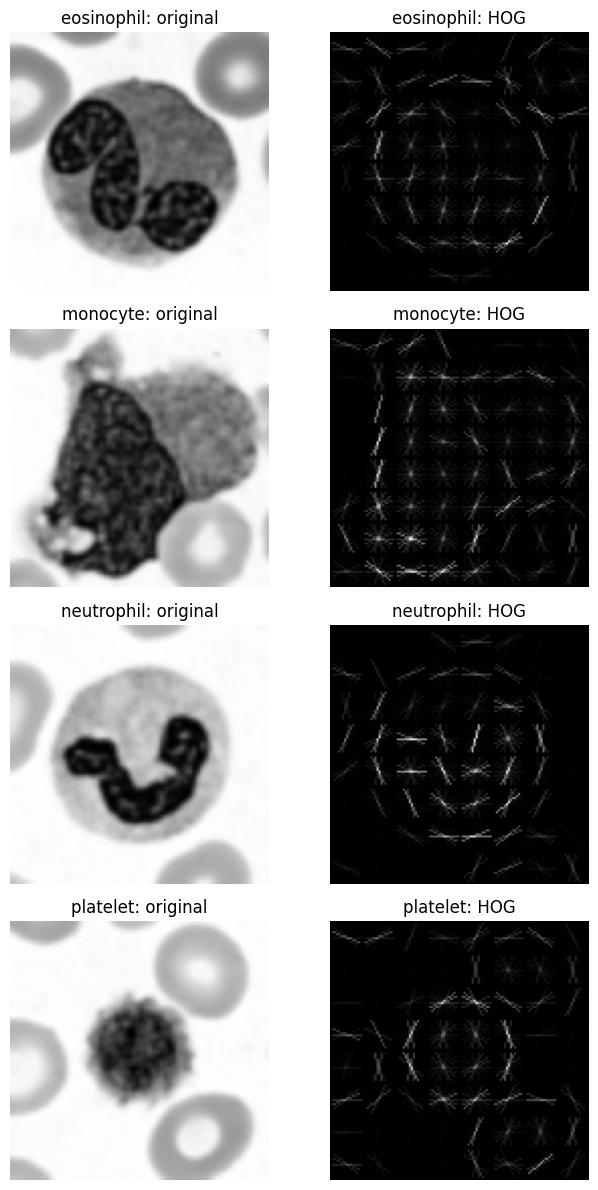

In [6]:
fig, axes = plt.subplots(len(CLASSES), 2, figsize=(7, 12))
for r, (lab, name) in enumerate(CLASSES.items()):
    i = np.where(y_train == lab)[0][0]
    _, hog_img = hog(X_train[i], orientations=HOG_ORIENT, pixels_per_cell=HOG_CELL,
                     cells_per_block=HOG_BLOCK, block_norm="L2-Hys", visualize=True)
    axes[r, 0].imshow(X_train[i], cmap="gray"); axes[r, 0].set_title(f"{name}: original"); axes[r, 0].axis("off")
    axes[r, 1].imshow(hog_img, cmap="gray");    axes[r, 1].set_title(f"{name}: HOG");      axes[r, 1].axis("off")
plt.tight_layout(); plt.show()

--- HOG + SVM: choosing C on VALIDATION set ---
C = 0.1   val acc = 0.7667   val macro-F1 = 0.7637
C = 1     val acc = 0.7500   val macro-F1 = 0.7482
C = 10    val acc = 0.7500   val macro-F1 = 0.7484

Best C = 0.1  |  Val accuracy = 0.7667  |  Val macro-F1 = 0.7637


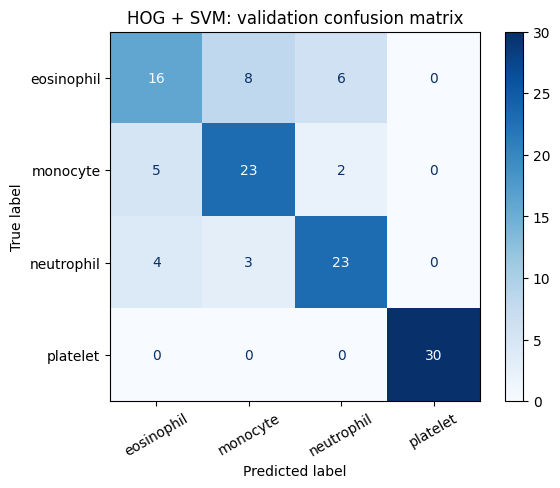

Confusion matrix:
 [[16  8  6  0]
 [ 5 23  2  0]
 [ 4  3 23  0]
 [ 0  0  0 30]]


In [7]:
def fit_select_C(F_tr, y_tr, F_va, y_va, name):
    best = None
    print(f"--- {name}: choosing C on VALIDATION set ---")
    for C in C_VALUES:
        clf = LinearSVC(C=C, dual=True, max_iter=20000, random_state=SEED)
        clf.fit(F_tr, y_tr)
        pred = clf.predict(F_va)
        acc = accuracy_score(y_va, pred)
        f1  = f1_score(y_va, pred, average="macro")
        print(f"C = {C:<5} val acc = {acc:.4f}   val macro-F1 = {f1:.4f}")
        if best is None or acc > best[1]:          # strict '>' keeps smaller C on ties
            best = (C, acc, f1, clf, pred)
    C, acc, f1, clf, pred = best
    print(f"\nBest C = {C}  |  Val accuracy = {acc:.4f}  |  Val macro-F1 = {f1:.4f}")
    cm = confusion_matrix(y_va, pred, labels=list(CLASSES))
    ConfusionMatrixDisplay(cm, display_labels=list(CLASSES.values())).plot(cmap="Blues", xticks_rotation=30)
    plt.title(f"{name}: validation confusion matrix"); plt.show()
    print("Confusion matrix:\n", cm)
    return clf, C, cm

hog_model, hog_C, cm_hog = fit_select_C(F_train_hog, y_train, F_val_hog, y_val, "HOG + SVM")

# Q3. SIFT + SVM

Average keypoints per image: 72.67
Minimum keypoints          : 8
Maximum keypoints          : 229
Images with zero keypoints : 0 out of 400


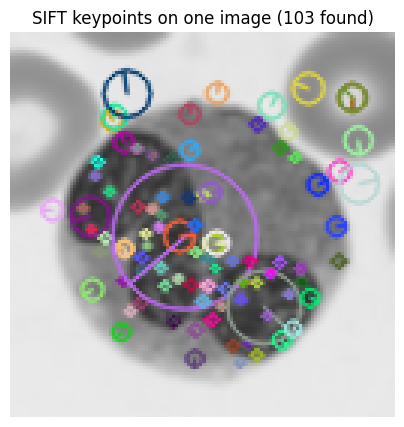

In [8]:
sift = cv2.SIFT_create()

kp_counts = []
for im in X_train:
    kps, des = sift.detectAndCompute(im, None)
    kp_counts.append(len(kps))
kp_counts = np.array(kp_counts)

print("Average keypoints per image:", round(kp_counts.mean(), 2))
print("Minimum keypoints          :", kp_counts.min())
print("Maximum keypoints          :", kp_counts.max())
print("Images with zero keypoints :", int((kp_counts == 0).sum()), "out of", len(kp_counts))

# draw keypoints on one image
im = X_train[0]
kps, _ = sift.detectAndCompute(im, None)
out = cv2.drawKeypoints(im, kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5)); plt.imshow(out); plt.axis("off")
plt.title(f"SIFT keypoints on one image ({len(kps)} found)"); plt.show()

**Why a different number of keypoints is a problem:** An SVM needs every image to be a feature vector of the same length, but normal SIFT gives each image a different number of 128-value descriptors (min <min> to max <max> here, with <zero_count> images having none), so the vectors cannot be stacked into one matrix.

Grid keypoints: 36
SIFT feature length per image: 4608
Train SIFT matrix: (400, 4608) | Val SIFT matrix: (120, 4608)


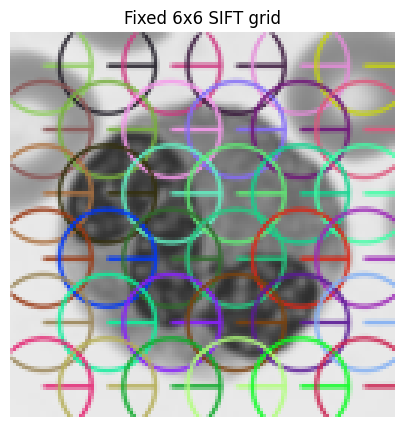

In [9]:
def make_grid_keypoints(n=SIFT_GRID, size=IMG_SIZE, kp_size=KP_SIZE):
    step = size / n
    pts = [(step * (j + 0.5), step * (i + 0.5)) for i in range(n) for j in range(n)]  # cell centres
    return [cv2.KeyPoint(float(x), float(y), kp_size, 0) for (x, y) in pts]

grid_kps = make_grid_keypoints()

def extract_sift_grid(img):
    _, des = sift.compute(img, grid_kps)
    assert des.shape == (SIFT_GRID**2, 128), des.shape
    return (des / 255.0).flatten()          # scale to about 0..1, join into one vector

def extract_sift_all(X):
    return np.array([extract_sift_grid(im) for im in X])

F_train_sift = extract_sift_all(X_train)
F_val_sift   = extract_sift_all(X_val)

print("Grid keypoints:", len(grid_kps))
print("SIFT feature length per image:", F_train_sift.shape[1])
print("Train SIFT matrix:", F_train_sift.shape, "| Val SIFT matrix:", F_val_sift.shape)

# picture of the grid (check)
vis = cv2.drawKeypoints(X_train[0], grid_kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5)); plt.imshow(vis); plt.axis("off"); plt.title("Fixed 6x6 SIFT grid"); plt.show()

### SIFT feature length: calculation by hand
- Grid = 6 x 6, so grid points = 36
- Each SIFT descriptor has 128 values (4 x 4 spatial bins x 8 orientations)
- **Feature length = 36 x 128 = 4608**

This matches the printed length of 4608.

--- SIFT (grid) + SVM: choosing C on VALIDATION set ---
C = 0.1   val acc = 0.8167   val macro-F1 = 0.8133
C = 1     val acc = 0.7833   val macro-F1 = 0.7853
C = 10    val acc = 0.8000   val macro-F1 = 0.8024

Best C = 0.1  |  Val accuracy = 0.8167  |  Val macro-F1 = 0.8133


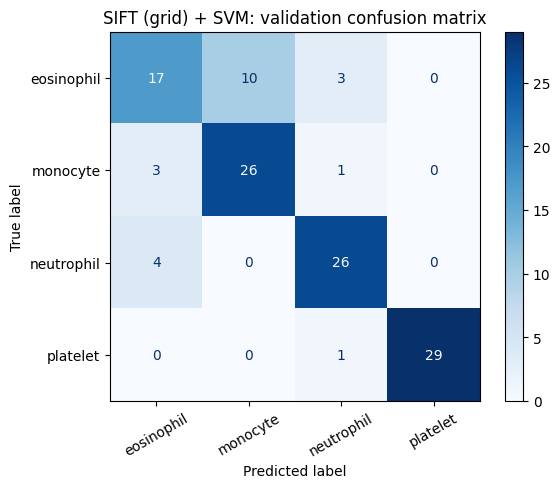

Confusion matrix:
 [[17 10  3  0]
 [ 3 26  1  0]
 [ 4  0 26  0]
 [ 0  0  1 29]]


In [10]:
sift_model, sift_C, cm_sift = fit_select_C(F_train_sift, y_train, F_val_sift, y_val, "SIFT (grid) + SVM")

# Q4. Robustness

### Prediction (written before running any test)
- **Rotation:** I think **HOG** will lose more accuracy, because HOG histograms are built from gradient directions, so rotating the image by 20° shifts the energy into different orientation bins and changes the feature vector.
- **Noise:** I think **HOG** will lose more accuracy, because HOG uses raw pixel differences with no smoothing, so noise adds strong random gradients everywhere, while SIFT blurs the image with Gaussian smoothing before computing gradients.

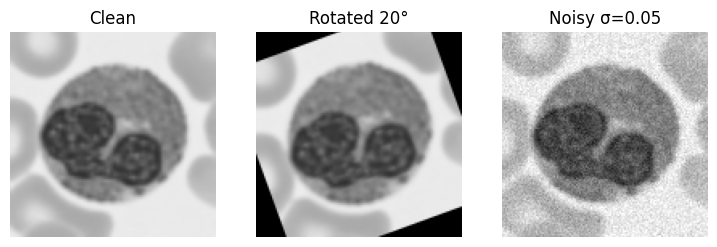

In [11]:
noise_rng = np.random.RandomState(SEED)

def rotate_images(X, angle=ROT_ANGLE):
    M = cv2.getRotationMatrix2D((IMG_SIZE / 2, IMG_SIZE / 2), angle, 1.0)
    return np.array([cv2.warpAffine(im, M, (IMG_SIZE, IMG_SIZE), borderValue=0) for im in X])

def add_noise(X, sigma=NOISE_SIGMA):
    Xf = X.astype(np.float32) / 255.0                       # scale to 0..1
    noisy = Xf + noise_rng.normal(0, sigma, Xf.shape)       # Gaussian noise, sigma = 0.05
    return (np.clip(noisy, 0, 1) * 255).round().astype(np.uint8)

X_test_rot   = rotate_images(X_test)
X_test_noisy = add_noise(X_test)

# visual check
fig, ax = plt.subplots(1, 3, figsize=(9, 3.2))
for a, im, t in zip(ax, [X_test[0], X_test_rot[0], X_test_noisy[0]], ["Clean", "Rotated 20°", "Noisy σ=0.05"]):
    a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(t); a.axis("off")
plt.show()

In [12]:
import pandas as pd

def evaluate(model, extractor, X, y):
    F = np.array([extractor(im) for im in X])               # features AFTER the change
    return accuracy_score(y, model.predict(F))

results = {}
for name, model, ext in [("HOG + SVM",  hog_model,  extract_hog),
                         ("SIFT + SVM", sift_model, extract_sift_grid)]:
    results[name] = [evaluate(model, ext, X_test,       y_test),
                     evaluate(model, ext, X_test_rot,   y_test),
                     evaluate(model, ext, X_test_noisy, y_test)]

table = pd.DataFrame(results, index=["Clean accuracy", "Rotated accuracy", "Noisy accuracy"]).T
table["Drop (rotation)"] = table["Clean accuracy"] - table["Rotated accuracy"]
table["Drop (noise)"]    = table["Clean accuracy"] - table["Noisy accuracy"]
print(table.round(4))

            Clean accuracy  Rotated accuracy  Noisy accuracy  Drop (rotation)  \
HOG + SVM           0.7250            0.6333          0.3667           0.0917   
SIFT + SVM          0.7833            0.4917          0.7833           0.2917   

            Drop (noise)  
HOG + SVM         0.3583  
SIFT + SVM        0.0000  


### Results table (test set, 120 images)
| Model | Clean accuracy | Rotated accuracy | Noisy accuracy |
|---|---|---|---|
| HOG + SVM  | <0.7250 > | <0.6333> | <0.3667> |
| SIFT + SVM | <0.7833> | <0.4917> | <0.7833> |

### Was my prediction correct?
My prediction was only half correct. For rotation I predicted HOG would lose more, but the table shows HOG dropped 0.0917 (0.7250 to 0.6333) while SIFT dropped 0.2917 (0.7833 to 0.4917), so SIFT lost more and I was wrong. For noise I predicted HOG would lose more, and this was correct: HOG dropped 0.3583 (0.7250 to 0.3667) while SIFT did not drop at all (0.7833 to 0.7833). Overall, SIFT was better on clean and noisy images but much weaker under rotation, so neither model was best in every case.